<a href="https://colab.research.google.com/github/Apekshagaonkar/ai-systems-notebooks/blob/main/week2_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 — Teaching a Computer to Guess the Weather
### Supervised ML: Regression

**The question for today:** *It's 6 a.m. The thermometer says 12 °C. How hot will it get this afternoon?*

| Time | Chapter | The question it answers |
|---|---|---|
| 0–5 | 0. The 6 a.m. question | Can last night predict today? |
| 5–12 | 1. Look before you learn | What is a pattern, and who writes the rule? |
| 12–22 | 2. Draw your own line | What does "learning" actually mean? |
| 22–30 | 3. Let scikit-learn do it | create → fit → predict |
| 30–42 | 4. The cheater | How do we know it learned, not memorized? |
| 42–54 | 5. More clues | What does each feature really add? |
| 54–60 | 6. Too simple, too clever + wrap-up | When does a model fool us? |

## Setup — run this first
This cell loads the tools and two years of daily weather for one city. Just run it.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Two years of daily weather for one city (generated so everyone gets identical data) ---
def load_weather():
    rng = np.random.default_rng(20)
    n = 730
    dates = pd.date_range("2024-01-01", periods=n, freq="D")
    season = -np.cos(2 * np.pi * (dates.dayofyear.values - 15) / 365)
    is_summer = dates.month.isin([6, 7, 8]).astype(int)
    swings = np.zeros(n)                       # weather systems come and go over days
    shocks = rng.normal(0, 5, n)
    for i in range(1, n):
        swings[i] = 0.7 * swings[i - 1] + shocks[i]
    temp_min = 10 + 4 * season + swings - 2.5 * is_summer
    rain = np.where(rng.random(n) < 0.3, rng.gamma(1.5, 4, n), 0.0) * (1 - 0.6 * is_summer)
    wind = np.clip(rng.normal(14, 6, n), 0, None)
    temp_max = 7 + 1.0 * temp_min + 3.0 * is_summer - 0.12 * rain - 0.10 * wind + rng.normal(0, 1.6, n)
    return pd.DataFrame({
        "date": dates, "temp_min": temp_min, "temp_max": temp_max,
        "rain_mm": rain.round(1), "wind_kmh": wind.round(1), "is_summer": is_summer,
    })

weather = load_weather()
pd.options.display.precision = 1
print(f"{len(weather)} days of weather loaded")
weather.head()

730 days of weather loaded


,date,temp_min,temp_max,rain_mm,wind_kmh,is_summer
0,2024-01-01,6.1,11.5,2.7,1.4,0
1,2024-01-02,12.1,14.6,0.0,13.6,0
2,2024-01-03,17.3,22.3,0.0,15.4,0
3,2024-01-04,15.5,22.5,0.0,18.1,0
4,2024-01-05,14.7,18.7,4.8,17.7,0


---
## 0. The 6 a.m. question  *(0–5 min)*

You wake up. Last night's lowest temperature was **12 °C**.

❓ **Before any code: how hot will it get today? Type a number in the chat.**

---
## 1. Look before you learn  *(5–12 min)*

A computer can't "live through" days, but it can read them. Each row is one day: what we **know at 6 a.m.** (the low) and what **actually happened** (the high).

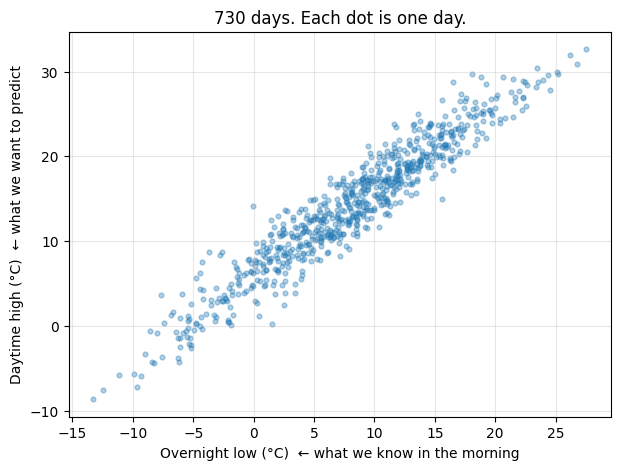

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(weather["temp_min"], weather["temp_max"], alpha=0.35, s=12)
plt.xlabel("Overnight low (°C)  ← what we know in the morning")
plt.ylabel("Daytime high (°C)  ← what we want to predict")
plt.title("730 days. Each dot is one day.")
plt.grid(alpha=0.3)
plt.show()

### Two ways to get a rule

| Old way (Week 1) | New way (today) |
|---|---|
| **You** write the rule: `def high(low): return low + 7` | **The data** writes the rule |
| Works if you already know the answer | Works when you only have examples |

This is **supervised learning**: every example comes *with the right answer attached* (we know each day's actual high). The answers "supervise" the learning.

There are two kinds of question you can ask:
- **Regression** → *how much?* → a number (today's high in °C)
- **Classification** → *which one?* → a category (will it rain: yes/no)


❓ **Quick-fire: regression or classification?**
1. The price of a flat
2. Whether an email is spam
3. How many minutes until the bus arrives
4. Which of 10 digits is in a picture

---
## 2. Draw your own line  *(12–22 min)*

The cloud looked like a line. A straight line has just two numbers:

$$\text{high} = \text{slope} \times \text{low} + \text{intercept}$$

- **slope**: how much the high goes up for each extra degree of low
- **intercept**: where the line starts

So "finding the rule" just means **finding two good numbers**. Let's try by hand.

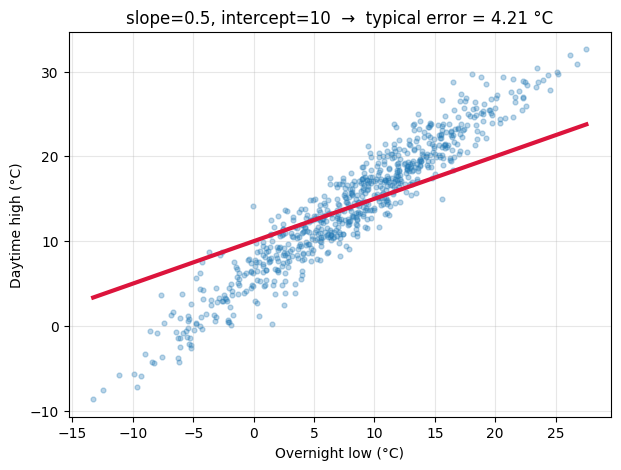

In [ ]:
lows  = weather["temp_min"].values
highs = weather["temp_max"].values

def try_line(slope, intercept):
    """Draw my guessed line and tell me how wrong it is on average."""
    guesses = slope * lows + intercept
    errors = highs - guesses
    rmse = np.sqrt(np.mean(errors ** 2))

    plt.figure(figsize=(7, 5))
    plt.scatter(lows, highs, alpha=0.3, s=12)
    xs = np.linspace(lows.min(), lows.max(), 50)
    plt.plot(xs, slope * xs + intercept, color="crimson", linewidth=3)
    plt.xlabel("Overnight low (°C)"); plt.ylabel("Daytime high (°C)")
    plt.title(f"slope={slope}, intercept={intercept}  →  typical error = {rmse:.2f} °C")
    plt.grid(alpha=0.3); plt.show()

try_line(slope=0.5, intercept=10)     # 👈 a first guess. Change these numbers!

❓ **That line is bad. What would you change? Shout out a better slope and intercept and we'll try them.**

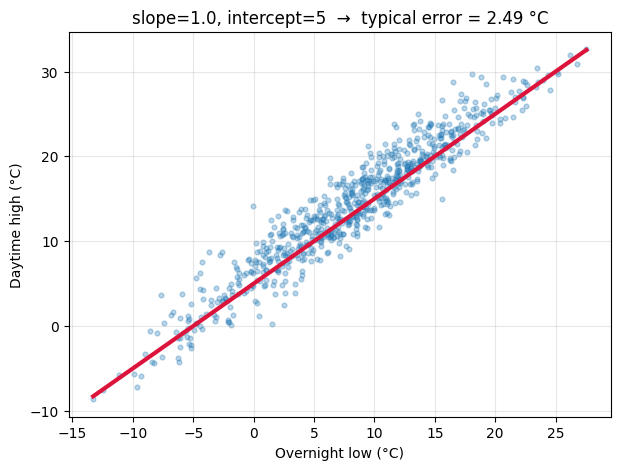

In [ ]:
try_line(slope=1.0, intercept=5)      # 👈 try the class's suggestions here"

### How wrong is a line? Measuring the error

For each day: **error = actual high − guessed high**.

$$\text{RMSE} = \sqrt{\text{average}(\text{error}^2)}$$

Square → so positive and negative misses don't cancel, and big misses count more.
Average → one number for all 730 days.
Square root → back to °C, so we can read it: *"typically off by 2 degrees."*

### Now let the computer guess, thousands of times

You tried 3 lines. A computer can try thousands and keep the best one. **That search is what "learning" means.**

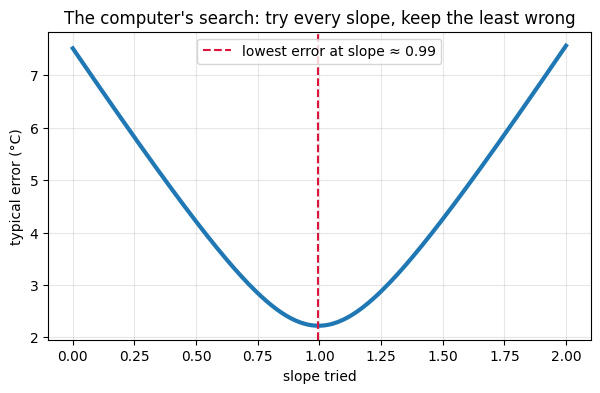

In [ ]:
# Try 200 different slopes (with the best intercept for each) and record the error
slopes = np.linspace(0, 2, 200)
errors_for_slope = []
for s in slopes:
    b = np.mean(highs - s * lows)                       # best intercept for this slope
    errors_for_slope.append(np.sqrt(np.mean((highs - (s * lows + b)) ** 2)))

best = slopes[np.argmin(errors_for_slope)]
plt.figure(figsize=(7, 4))
plt.plot(slopes, errors_for_slope, linewidth=3)
plt.axvline(best, color="crimson", linestyle="--", label=f"lowest error at slope ≈ {best:.2f}")
plt.xlabel("slope tried"); plt.ylabel("typical error (°C)")
plt.title("The computer's search: try every slope, keep the least wrong")
plt.legend(); plt.grid(alpha=0.3); plt.show()

---
## 3. Let scikit-learn do it  *(22–30 min)*

scikit-learn has done this search for us. Every model in it, now and in Week 3, follows the same three steps:

```python
model = LinearRegression()   # 1. create  — an empty model, knows nothing yet
model.fit(X, y)              # 2. fit     — search for the best numbers (the valley!)
model.predict(X_new)         # 3. predict — use those numbers on new days
```

Sound familiar? `LinearRegression` is a **class** (Week 1). `fit` changes its state. `predict` uses that state.

Let's try it, the obvious way first:

In [ ]:
from sklearn.linear_model import LinearRegression

x = weather["temp_min"].values      # the lows
y = weather["temp_max"].values      # the highs
print("shape of x:", x.shape)

model = LinearRegression()
try:
    model.fit(x, y)
except ValueError as e:
    print("\n💥 ValueError:", str(e).splitlines()[0])

shape of x: (730,)

💥 ValueError: Expected 2D array, got 1D array instead:


❓ **It crashed. The shape is `(730,)`. What do you think scikit-learn wanted instead?**

In [ ]:
X = x.reshape(-1, 1)    # -1 = "work out the rows yourself", 1 = "one column"
print("shape of X:", X.shape)

model = LinearRegression()      # create
model.fit(X, y)                 # fit
print(f"slope     = {model.coef_[0]:.2f}")
print(f"intercept = {model.intercept_:.2f}")

print(f"\nPrediction for a 12 °C morning: {model.predict([[12]])[0]:.1f} °C")

shape of X: (730, 1)
slope     = 1.00
intercept = 6.16

Prediction for a 12 °C morning: 18.1 °C


---
## 4. The cheater

Here's a different model. Its rule is simple: *"For a new day, find the most similar day I've already seen and copy its answer."*

Let's score it on the data it learned from.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error

cheater = KNeighborsRegressor(n_neighbors=1)   # "copy the single closest day"
cheater.fit(X, y)

line = LinearRegression().fit(X, y)

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

print(f"Copy-the-closest-day error on days it has seen: {rmse(y, cheater.predict(X)):.2f} °C")
print(f"Straight line error on days it has seen:        {rmse(y, line.predict(X)):.2f} °C")

Copy-the-closest-day error on days it has seen: 0.00 °C
Straight line error on days it has seen:        2.22 °C


### Hide some days: the train/test split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42      # hide 20% of days; same split for everyone
)
print(f"Days to learn from: {len(X_train)}   Days hidden for the exam: {len(X_test)}")

cheater = KNeighborsRegressor(n_neighbors=1).fit(X_train, y_train)
line    = LinearRegression().fit(X_train, y_train)

print("\n                   seen days   hidden days")
print(f"Copier             {rmse(y_train, cheater.predict(X_train)):6.2f} °C   {rmse(y_test, cheater.predict(X_test)):6.2f} °C")
print(f"Straight line      {rmse(y_train, line.predict(X_train)):6.2f} °C   {rmse(y_test, line.predict(X_test)):6.2f} °C")

Days to learn from: 584   Days hidden for the exam: 146

                   seen days   hidden days
Copier               0.00 °C     3.09 °C
Straight line        2.22 °C     2.22 °C


### Is 2 °C good? We need a baseline

An error of ~2 °C sounds good, but compared to what? The laziest possible forecaster ignores the low and **always predicts the average high**. Any model worth using must beat that.

That comparison has a name, **R²**:

$$R^2 = 1 - \frac{\text{model's squared error}}{\text{lazy forecaster's squared error}}$$

- **1.0** → perfect
- **0.0** → no better than always guessing the average
- **below 0** → *worse* than the lazy forecaster

In [ ]:
y_pred = line.predict(X_test)

model_error = np.sum((y_test - y_pred) ** 2)
lazy_error  = np.sum((y_test - y_test.mean()) ** 2)    # always guess the average high
print(f"R² by hand:          {1 - model_error / lazy_error:.3f}")
print(f"R² from scikit-learn: {r2_score(y_test, y_pred):.3f}")
print(f"RMSE:                {rmse(y_test, y_pred):.2f} °C")

R² by hand:          0.917
R² from scikit-learn: 0.917
RMSE:                2.22 °C


---
## 5. More features  

Remember the band had thickness: same low, different highs. A real forecaster also looks out the window. Let's give the model more features: **rain**, **wind**, and **is it summer?**


In [ ]:
features = ["temp_min", "rain_mm", "wind_kmh", "is_summer"]
X4 = weather[features]          # a table with 4 columns: same shape idea, more clues

X4_train, X4_test, y_train, y_test = train_test_split(X4, y, test_size=0.2, random_state=42)

model4 = LinearRegression()         # create
model4.fit(X4_train, y_train)       # fit
y4_pred = model4.predict(X4_test)   # predict   ← exactly the same three lines!

print(f"RMSE: {rmse(y_test, y4_pred):.2f} °C   (one clue: {rmse(y_test, y_pred):.2f})")
print(f"R²:   {r2_score(y_test, y4_pred):.3f}   (one clue: {r2_score(y_test, y_pred):.3f})\n")
for name, coef in zip(features, model4.coef_):
    print(f"{name:>10}: {coef:+.2f}")

RMSE: 1.67 °C   (one clue: 2.22)
R²:   0.953   (one clue: 0.917)

  temp_min: +1.00
   rain_mm: -0.14
  wind_kmh: -0.11
 is_summer: +3.00


---
## 6. Too simple, too clever

We've now seen both ways a model can fool us:

| | What it does | Seen days | Hidden days |
|---|---|---|---|
| **Underfit** (too simple) | Misses the real pattern, e.g. always guessing the average | bad | bad |
| **Good fit** | Learns the pattern, ignores the noise | good | good |
| **Overfit** (too clever) | Memorizes the noise, like our copier | great | bad |

**The warning sign: a big gap between the score on seen days and on hidden days.**

In [ ]:
for name, m in [("Straight line (4 clues)", LinearRegression()),
                ("Copier (4 clues)",        KNeighborsRegressor(n_neighbors=1))]:
    m.fit(X4_train, y_train)
    tr, te = r2_score(y_train, m.predict(X4_train)), r2_score(y_test, m.predict(X4_test))
    print(f"{name:<25} seen R² = {tr:.3f}   hidden R² = {te:.3f}   gap = {tr - te:.3f}")

Straight line (4 clues)   seen R² = 0.954   hidden R² = 0.953   gap = 0.001
Copier (4 clues)          seen R² = 1.000   hidden R² = 0.854   gap = 0.146


---
## Wrap-up

1. **Learning = searching** for the numbers that make a model least wrong (the valley).
2. Every scikit-learn model: **create → fit → predict**, with **X as a 2D table**.
3. **Judge on hidden days**: train/test split, or the cheater wins.
4. **RMSE** = typical miss, in °C. **R²** = how much better than guessing the average.
5. A **coefficient** is one clue's effect *with the others held fixed*.
6. Watch the **train vs test gap** for overfitting.

### Next week
Same weather, same three lines of code, a different question: *"Will it rain tomorrow — yes or no?"* That's **classification**.

### Think about before next time
- Why can't we judge a model on the days it trained on?
- If R² on test data is −0.5, what does that tell you?
- A feature has a correlation of 0.05 with the target. Should you delete it?